pandas introduction

In [1]:
import pandas as pd

# Creiamo un dizionario con dati di esempio
dati = {
    'Campione': [1, 2, 3, 4],
    'Feature_A': [10.5, 12.0, 9.8, 11.2],
    'Feature_B': [50, 42, 55, 48],
    'Target_Classe': ['OK', 'KO', 'OK', 'OK']
}

# Creazione del DataFrame
df = pd.DataFrame(dati)

# Visualizzazione della tabella
print("Il nostro primo DataFrame in Pandas:")
display(df)
# Estraiamo la colonna dei valori della Feature_A
feature_a = df['Feature_A']
print(feature_a)

# Filtriamo solo le righe dove Target_Classe è uguale a 'OK'
df_ok = df[df['Target_Classe'] == 'OK']
print("Statistiche descrittive della Feature_A per i campioni con Target_Classe 'OK':")
print('------- display(df_ok) ------------')
display(df_ok)
print('-------- print(df_ok) -----------')
print(df_ok)
print('-------- print(df_ok[\'Feature_A\'].describe()) -----------')
print(df_ok['Feature_A'].describe())
# Mostra conteggio, media, deviazione standard, min, max e percentili
print('-------- print(df.describe()) -----------')
print(df.describe())



Il nostro primo DataFrame in Pandas:


,Campione,Feature_A,Feature_B,Target_Classe
0,1,10.5,50,OK
1,2,12.0,42,KO
2,3,9.8,55,OK
3,4,11.2,48,OK


0    10.5
1    12.0
2     9.8
3    11.2
Name: Feature_A, dtype: float64
Statistiche descrittive della Feature_A per i campioni con Target_Classe 'OK':
------- display(df_ok) ------------


,Campione,Feature_A,Feature_B,Target_Classe
0,1,10.5,50,OK
2,3,9.8,55,OK
3,4,11.2,48,OK


-------- print(df_ok) -----------
   Campione  Feature_A  Feature_B Target_Classe
0         1       10.5         50            OK
2         3        9.8         55            OK
3         4       11.2         48            OK
-------- print(df_ok['Feature_A'].describe()) -----------
count     3.00
mean     10.50
std       0.70
min       9.80
25%      10.15
50%      10.50
75%      10.85
max      11.20
Name: Feature_A, dtype: float64
-------- print(df.describe()) -----------
       Campione  Feature_A  Feature_B
count  4.000000   4.000000   4.000000
mean   2.500000  10.875000  48.750000
std    1.290994   0.942956   5.377422
min    1.000000   9.800000  42.000000
25%    1.750000  10.325000  46.500000
50%    2.500000  10.850000  49.000000
75%    3.250000  11.400000  51.250000
max    4.000000  12.000000  55.000000


pandas cvs management

In [25]:
import pandas as pd

# Carichiamo il file CSV presente nella cartella del progetto
df_csv = pd.read_csv('dati.csv', sep=';')

# Visualizziamo le prime n righe del dataset per un controllo rapido
print("Prime n righe del dataset:")
display(df_csv.head(3))

print(df_csv.iloc[1:2, 1:2],'\n')
# header non viene considerato come riga del DataFrame, 
# quindi la riga 1 corrisponde alla seconda riga del file CSV ed 
# ha indice 0 nel DataFrame.
x = df_csv.iloc[0:1, 0:1]
print(x,'\n')
print(x.values[0][0],'\n')

y = df_csv.iloc[1, 1]
print(y,'\n')


# Vediamo informazioni generali sulla struttura (tipi di dati e valori nulli)
print("Informazioni generali sul DataFrame:")
df_csv.info()

Prime n righe del dataset:


,Col1,Col2,Col3
0,1.50000,2.0,3.1089
1,4.20178,5.5,6.0000
2,5.00000,6.0,7.2000


   Col2
1   5.5 

   Col1
0   1.5 

1.5 

5.5 

Informazioni generali sul DataFrame:
<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Col1    3 non-null      float64
 1   Col2    3 non-null      float64
 2   Col3    3 non-null      float64
dtypes: float64(3)
memory usage: 204.0 bytes


add new row

In [31]:
import pandas as pd

# Carichiamo il file CSV presente nella cartella del progetto
df_csv = pd.read_csv('dati.csv', sep=';')

# 1. Definiamo la nuova riga come un piccolo DataFrame (con le stesse colonne)
nuova_riga = pd.DataFrame([{'Col1': -2, 'Col2': 1.5, 'Col3': 30}])

# 2. Concateniamo il vecchio DataFrame con la nuova riga
# ignore_index=True serve a rinumerare correttamente le righe in sequenza (0, 1, 2, 3...)
df_csv = pd.concat([df_csv, nueva_riga] if 'nueva_riga' in locals() else [df_csv, nuova_riga], ignore_index=True)

# Semplificato:
df_csv = pd.concat([df_csv, nuova_riga*2], ignore_index=True)

# 3. Vediamo il risultato aggiornato
display(df_csv.tail())  # .tail() mostra le ultime righe

df_csv.to_csv('dati2.csv', sep=';', index=False)
df_csv.to_csv('dati3.csv', sep=';', index=True)

print("File salvato con successo!")

,Col1,Col2,Col3
0,1.50000,2.0,3.1089
1,4.20178,5.5,6.0000
2,5.00000,6.0,7.2000
3,-2.00000,1.5,30.0000
4,-4.00000,3.0,60.0000


File salvato con successo!


OOP for program with CVS and pandas

In [ ]:
import pandas as pd

class DatasetManager:
    """Classe orientata agli oggetti per caricare, modificare e salvare dataset."""
    
    def __init__(self, filepath, sep=';'):
        self.filepath = filepath
        self.sep = sep
        self.df = None
        
    def load_data(self):
        """Carica il file CSV in un DataFrame."""
        self.df = pd.read_csv(self.filepath, sep=self.sep)
        print(f"Dataset '{self.filepath}' caricato correttamente.")
        
    def add_row(self, row_data):
        """Aggiunge una nuova riga passando un dizionario."""
        nuova_riga = pd.DataFrame([row_data])
        self.df = pd.concat([self.df, nuova_riga], ignore_index=True)
        print("Nuova riga aggiunta con successo.")
        
    def show_tail(self, n=5):
        """Mostra le ultime righe del DataFrame."""
        display(self.df.tail(n))
        
    def save_data(self, output_path, include_index=False):
        """Salva il DataFrame modificato su un nuovo file CSV."""
        self.df.to_csv(output_path, sep=self.sep, index=include_index)
        print(f"File salvato con successo come '{output_path}'.")

# ==========================================
# Utilizzo pratico della classe
# ==========================================

# 1. Istanziamo l'oggetto
manager = DatasetManager('dati.csv', sep=';')

# 2. Carichiamo i dati
manager.load_data()

# 3. Aggiungiamo una riga usando un dizionario
manager.add_row({'Col1': -2.0, 'Col2': 1.5, 'Col3': 30.0})

# 4. Visualizziamo la fine del DataFrame
manager.show_tail()

# 5. Salviamo il nuovo file
manager.save_data('dati_oop_output.csv', include_index=False)

Dataset 'dati.csv' caricato correttamente.
Nuova riga aggiunta con successo.


,Col1,Col2,Col3
0,1.50000,2.0,3.1089
1,4.20178,5.5,6.0000
2,5.00000,6.0,7.2000
3,-2.00000,1.5,30.0000


File salvato con successo come 'dati_oop_output.csv'.


use panda in a OOP program

In [2]:
import pandas as pd

class DataAnalyzer:
    """
    Classe didattica per l'analisi esplorativa dei dati (EDA).
    Incapsula un DataFrame di Pandas e fornisce metodi strutturati 
    per la visualizzazione e il filtraggio pulito dei dati.
    """
    
    def __init__(self, dataframe):
        """
        Il costruttore (__init__) viene eseguito quando istanziamo la classe.
        Salva il DataFrame come attributo dell'oggetto (self.df), rendendolo
        accessibile a tutti gli altri metodi della classe.
        """
        self.df = dataframe
        
    def show_summary(self):
        """
        Metodo per stampare una panoramica generale del dataset:
        - Mostra la tabella completa interattiva (tramite display)
        - Calcola le statistiche descrittive di base (conteggio, media, std, min, max, percentili)
          per tutte le colonne numeriche.
        """
        print("--- [PANORAMICA] Il nostro primo DataFrame in Pandas ---")
        display(self.df)
        
        print("\n--- [STATISTICHE GENERALI] print(self.df.describe()) ---")
        # .describe() ignora automaticamente le colonne di tipo stringa/oggetto 
        # e analizza solo quelle numeriche.
        print(self.df.describe())
        
    def filter_and_analyze(self, column_name, condition_value, target_feature):
        """
        Filtra il DataFrame applicando una condizione booleana e restituisce
        un sotto-insieme (subset) di dati su cui calcolare statistiche mirate.
        """
        print(f"\n--- [FILTRAGGIO] Selezioniamo le righe dove '{column_name}' == '{condition_value}' ---")
        
        # 1. Filtraggio condizionale (Boolean Indexing):
        # self.df[column_name] == condition_value crea una serie di True/False.
        # Passandola dentro self.df[...] estraiamo solo le righe che soddisfano la condizione.
        df_filtered = self.df[self.df[column_name] == condition_value]
        
        # 2. Mostriamo il DataFrame filtrato
        display(df_filtered)
        
        print(f"--- [STATISTICHE MIRATE] Analizziamo la colonna '{target_feature}' sul filtrato ---")
        
        # 3. Estraiamo la singola colonna (Series) e calcoliamo le statistiche descrittive
        target_description = df_filtered[target_feature].describe()
        print(target_description)
        
        # Restituiamo il DataFrame filtrato nel caso volessimo usarlo per altri calcoli
        return df_filtered


# =====================================================================
# BLOCCO PRINCIPALE (Main) - Utilizzo pratico della classe nel Notebook
# =====================================================================

# 1. Creiamo un dizionario di dati grezzi di esempio
dati = {
    'Campione': [1, 2, 3, 4],
    'Feature_A': [10.5, 12.0, 9.8, 11.2],
    'Feature_B': [50, 42, 55, 48],
    'Target_Classe': ['OK', 'KO', 'OK', 'OK']
}

# 2. Convertiamo il dizionario in un DataFrame di Pandas
df_principale = pd.DataFrame(dati)

# 3. Istanziamo l'oggetto 'analyzer' passando il DataFrame al costruttore
analyzer = DataAnalyzer(df_principale)

# 4. Richiamiamo il primo metodo per la panoramica generale
analyzer.show_summary()

# 5. Richiamiamo il metodo di filtraggio avanzato per isolare solo i campioni 'OK'
df_ok = analyzer.filter_and_analyze(
    column_name='Target_Classe', 
    condition_value='OK', 
    target_feature='Feature_A'
)

--- [PANORAMICA] Il nostro primo DataFrame in Pandas ---


,Campione,Feature_A,Feature_B,Target_Classe
0,1,10.5,50,OK
1,2,12.0,42,KO
2,3,9.8,55,OK
3,4,11.2,48,OK



--- [STATISTICHE GENERALI] print(self.df.describe()) ---
       Campione  Feature_A  Feature_B
count  4.000000   4.000000   4.000000
mean   2.500000  10.875000  48.750000
std    1.290994   0.942956   5.377422
min    1.000000   9.800000  42.000000
25%    1.750000  10.325000  46.500000
50%    2.500000  10.850000  49.000000
75%    3.250000  11.400000  51.250000
max    4.000000  12.000000  55.000000

--- [FILTRAGGIO] Selezioniamo le righe dove 'Target_Classe' == 'OK' ---


,Campione,Feature_A,Feature_B,Target_Classe
0,1,10.5,50,OK
2,3,9.8,55,OK
3,4,11.2,48,OK


--- [STATISTICHE MIRATE] Analizziamo la colonna 'Feature_A' sul filtrato ---
count     3.00
mean     10.50
std       0.70
min       9.80
25%      10.15
50%      10.50
75%      10.85
max      11.20
Name: Feature_A, dtype: float64


Programma che rappresenta seno e coseno

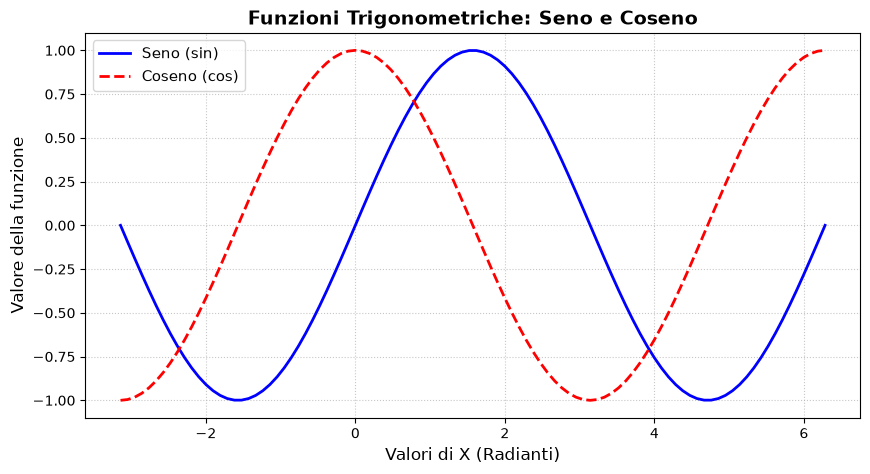

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Generazione dei dati con NumPy
# Creiamo un array di 100 punti che vanno da 0 a 2*pi greco (un ciclo completo)
x = np.linspace(-np.pi, 2 * np.pi, 100)

# Calcoliamo i valori corrispondenti per il seno e il coseno
y_seno = np.sin(x)
y_coseno = np.cos(x)

# 2. Configurazione e creazione del grafico con Matplotlib
plt.figure(figsize=(10, 5)) # Definisce le dimensioni della finestra del grafico (larghezza, altezza)

# Tracciamo la curva del Seno
plt.plot(x, y_seno, label='Seno (sin)', color='blue', linewidth=2, linestyle='-')

# Tracciamo la curva del Coseno
plt.plot(x, y_coseno, label='Coseno (cos)', color='red', linewidth=2, linestyle='--')

# 3. Personalizzazione del grafico (Elementi essenziali)
plt.title('Funzioni Trigonometriche: Seno e Coseno', fontsize=14, fontweight='bold')
plt.xlabel('Valori di X (Radianti)', fontsize=12)
plt.ylabel('Valore della funzione', fontsize=12)

# Aggiungiamo una griglia per facilitare la lettura visiva
plt.grid(True, linestyle=':', alpha=0.7)

# Mostriamo la legenda per distinguere le curve
plt.legend(fontsize=11)

# 4. Visualizzazione finale
plt.show()

--- [PANORAMICA] DataFrame principale ---


,Campione,Feature_A,Feature_B,Target_Classe
0,1,10.5,50,OK
1,2,12.0,42,KO
2,3,9.8,55,OK
3,4,11.2,48,OK
4,5,14.5,60,KO
5,6,8.1,39,OK
6,7,10.9,52,OK
7,8,13.4,47,KO



--- [STATISTICHE] ---
       Campione  Feature_A  Feature_B
count   8.00000   8.000000   8.000000
mean    4.50000  11.300000  49.125000
std     2.44949   2.015653   6.770472
min     1.00000   8.100000  39.000000
25%     2.75000  10.325000  45.750000
50%     4.50000  11.050000  49.000000
75%     6.25000  12.350000  52.750000
max     8.00000  14.500000  60.000000

--- [GRAFICO] Analisi visiva della feature: 'Feature_A' ---


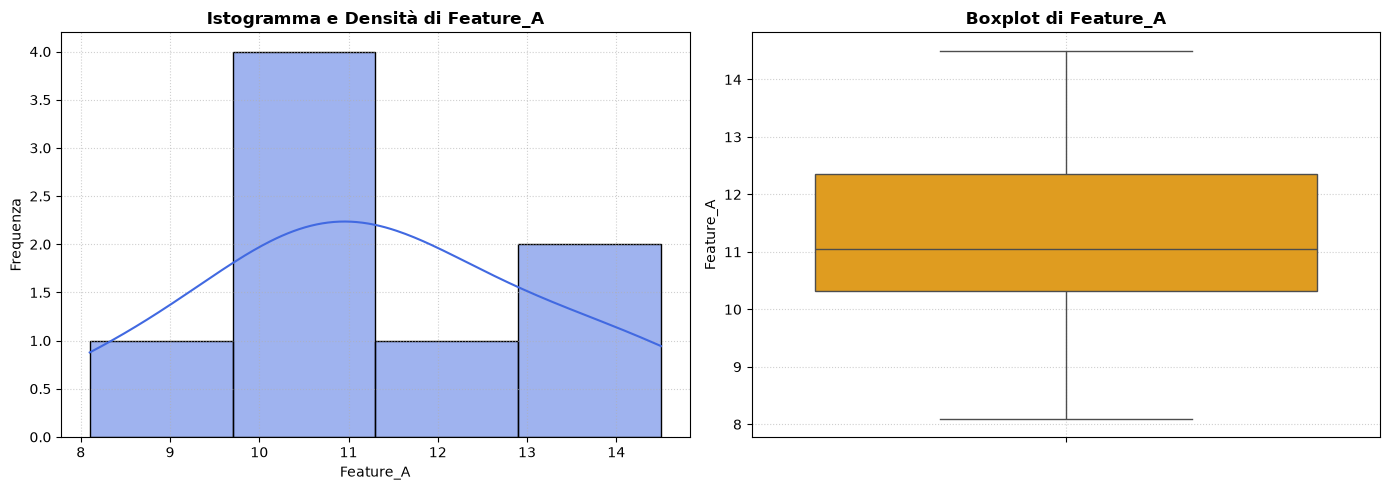

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

class DataAnalyzer:
    """
    Classe didattica avanzata per l'analisi esplorativa dei dati (EDA) 
    e la visualizzazione grafica integrata.
    """
    
    def __init__(self, dataframe):
        """Costruttore: riceve il DataFrame e lo salva come attributo dell'oggetto."""
        self.df = dataframe
        
    def show_summary(self):
        """Stampa la panoramica generale e le statistiche descrittive."""
        print("--- [PANORAMICA] DataFrame principale ---")
        display(self.df)
        print("\n--- [STATISTICHE] ---")
        print(self.df.describe())
        
    def plot_feature_distribution(self, target_feature):
        """
        Metodo OOP per generare grafici statistici (Istogramma + Boxplot) 
        di una specifica colonna numerica usando Seaborn e Matplotlib.
        """
        print(f"\n--- [GRAFICO] Analisi visiva della feature: '{target_feature}' ---")
        
        # Creiamo una figura con 2 sotto-grafici affiancati (1 riga, 2 colonne)
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        
        # 1. Grafico a sinistra: Istogramma con curva di densità (KDE)
        sns.histplot(self.df[target_feature], kde=True, ax=axes[0], color='royalblue')
        axes[0].set_title(f'Istogramma e Densità di {target_feature}', fontsize=12, fontweight='bold')
        axes[0].set_xlabel(target_feature, fontsize=10)
        axes[0].set_ylabel('Frequenza', fontsize=10)
        axes[0].grid(True, linestyle=':', alpha=0.6)
        
        # 2. Grafico a destra: Boxplot (ottimo per vedere mediana, quartili e outlier)
        sns.boxplot(y=self.df[target_feature], ax=axes[1], color='orange')
        axes[1].set_title(f'Boxplot di {target_feature}', fontsize=12, fontweight='bold')
        axes[1].set_ylabel(target_feature, fontsize=10)
        axes[1].grid(True, linestyle=':', alpha=0.6)
        
        # Ottimizza lo spaziamento tra i grafici per evitare sovrapposizioni
        plt.tight_layout()
        
        # Mostra il risultato grafico nel notebook
        plt.show()


# =====================================================================
# BLOCCO PRINCIPALE (Main) - Testiamo la nuova classe con i grafici
# =====================================================================

# 1. Creiamo un dataset di esempio un po' più ricco
dati = {
    'Campione': [1, 2, 3, 4, 5, 6, 7, 8],
    'Feature_A': [10.5, 12.0, 9.8, 11.2, 14.5, 8.1, 10.9, 13.4],
    'Feature_B': [50, 42, 55, 48, 60, 39, 52, 47],
    'Target_Classe': ['OK', 'KO', 'OK', 'OK', 'KO', 'OK', 'OK', 'KO']
}

# 2. Istanziamo il DataFrame e la classe DataAnalyzer
df_principale = pd.DataFrame(dati)
analyzer = DataAnalyzer(df_principale)

# 3. Stampiamo il sommario testuale
analyzer.show_summary()

# 4. Richiamiamo il nuovo metodo per generare i grafici sulla 'Feature_A'
analyzer.plot_feature_distribution(target_feature='Feature_A')